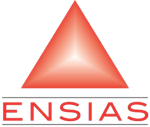

# TP 6 — Clustering avec K-means

**Module :** Introduction au Machine Learning
**Enseignant :** Prof. Aissam BERRAHOU — ENSIAS, Université Mohammed V de Rabat
**Niveau :** 2e année cycle ingénieur
**Durée estimée :** 2 heures
**Support associé :** Lecture 6 — K-means

## 1. Objectifs pédagogiques

*Ce TP prolonge le cours : vous allez refaire sur machine les calculs vus en séance, puis passer à un vrai jeu de données.*

À la fin de ce TP, vous serez capable de :

1. Implémenter K-means **« from scratch »** avec NumPy, étape par étape.
2. Vérifier vos résultats avec `sklearn.cluster.KMeans`.
3. Calculer et interpréter l'**inertie intra-classe** $W$ et le **score de silhouette**.
4. Mettre en évidence le problème des **minima locaux** et le rôle de l'initialisation.
5. Choisir le nombre de clusters $K$ sur un jeu de données réel (Iris).

## 2. Rappel théorique

*Avant de coder, un rapide rappel des formules dont nous aurons besoin.*

On cherche à répartir $n$ points $x_1, \dots, x_n$ en $K$ groupes $C_1, \dots, C_K$ de centroïdes $\mu_1, \dots, \mu_K$.

**Critère minimisé : l'inertie intra-classe**

$$W = \sum_{k=1}^{K} \sum_{x_i \in C_k} \lVert x_i - \mu_k \rVert^2$$

**Algorithme**

1. Choisir $K$ centroïdes initiaux.
2. **Affectation** : chaque point rejoint le centroïde le plus proche.
3. **Mise à jour** : $\mu_k = \dfrac{1}{N_k} \sum_{x_i \in C_k} x_i$ (moyenne des points du groupe).
4. Répéter 2 et 3 tant que les centroïdes bougent.

**Score de silhouette** d'un point $i$ :

$$s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}$$

- $a(i)$ : distance moyenne aux autres points de son cluster ;
- $b(i)$ : distance moyenne aux points du cluster voisin le plus proche.

Le score global $S$ est la moyenne des $s(i)$ ; il est compris entre $-1$ et $1$ (plus il est grand, mieux c'est).

## 3. Import des bibliothèques

*On charge d'abord les outils. Tout le TP n'utilise que NumPy, pandas, Matplotlib et scikit-learn.*

On utilise uniquement NumPy, pandas, Matplotlib et scikit-learn.

In [1]:
import numpy as np                      # calcul numérique
import pandas as pd                     # affichage des tableaux
import matplotlib.pyplot as plt         # graphiques

from sklearn.cluster import KMeans                  # K-means de scikit-learn
from sklearn.datasets import load_iris              # jeu de données Iris
from sklearn.metrics import silhouette_score, silhouette_samples
from sklearn.metrics import adjusted_rand_score     # comparaison avec les vraies classes
from sklearn.preprocessing import StandardScaler    # standardisation

np.set_printoptions(precision=2, suppress=True)     # affichage à 2 décimales

## 4. Exemple jouet : les 6 fleurs du cours

*Peut-on séparer nos six fleurs en deux familles ? Refaisons le calcul du cours, à la machine.*

On reprend **exactement** l'exemple des slides : 6 fleurs décrites par la taille des pétales et la taille de la tige.

In [2]:
# Chaque ligne = une fleur : (taille des pétales, taille de la tige)
X_fleurs = np.array([[22, 17], [27, 25], [25, 24],
                     [15, 35], [13, 25], [12, 30]], dtype=float)
noms = ["O1", "O2", "O3", "O4", "O5", "O6"]

# Affichage sous forme de tableau
pd.DataFrame(X_fleurs, index=noms, columns=["T. pétales", "T. tige"])

,T. pétales,T. tige
O1,22.0,17.0
O2,27.0,25.0
O3,25.0,24.0
O4,15.0,35.0
O5,13.0,25.0
O6,12.0,30.0


### 4.1 Les briques de l'algorithme

*K-means tient en quatre petites fonctions. Écrivons-les une par une.*

On écrit une petite fonction pour chaque étape. D'abord, la **matrice des distances** entre chaque point et chaque centroïde.

In [3]:
def calculer_distances(X, centroides):
    """Renvoie une matrice (n, K) : distance euclidienne de chaque point à chaque centroïde."""
    distances = np.zeros((len(X), len(centroides)))
    for k, mu in enumerate(centroides):
        # norme de (x_i - mu_k) pour tous les points d'un coup
        distances[:, k] = np.sqrt(((X - mu) ** 2).sum(axis=1))
    return distances

**Affectation** : chaque point rejoint le centroïde le plus proche (indice de la plus petite distance).

In [4]:
def affecter(distances):
    """Renvoie le numéro du cluster (0, 1, ...) de chaque point."""
    return np.argmin(distances, axis=1)

**Inertie** $W$ : somme des carrés des distances de chaque point à **son** centroïde.

In [5]:
def calculer_inertie(distances, etiquettes):
    """W = somme des d(x_i, mu_k)^2 avec k le cluster du point i."""
    d_propre = distances[np.arange(len(etiquettes)), etiquettes]  # distance à son centroïde
    return np.sum(d_propre ** 2)

**Mise à jour** : chaque centroïde devient la moyenne des points de son groupe.

In [6]:
def mettre_a_jour(X, etiquettes, K):
    """Nouveau centroïde = moyenne des points du cluster."""
    nouveaux = np.zeros((K, X.shape[1]))
    for k in range(K):
        nouveaux[k] = X[etiquettes == k].mean(axis=0)
    return nouveaux

### 4.2 L'algorithme complet

*Il ne reste plus qu'à les assembler et à laisser tourner jusqu'à ce que plus rien ne bouge.*

On assemble les briques. À chaque itération, on affiche le tableau des distances (comme dans les slides) et la valeur de $W$.

In [7]:
def kmeans_scratch(X, centroides_init, max_iter=10, afficher=True):
    """K-means pas à pas. Renvoie (centroides, etiquettes, historique de W)."""
    centroides = centroides_init.astype(float)
    historique_W = []
    for it in range(1, max_iter + 1):
        distances = calculer_distances(X, centroides)   # étape 2a : distances
        etiquettes = affecter(distances)                # étape 2b : affectation
        W = calculer_inertie(distances, etiquettes)     # étape 3 : inertie
        historique_W.append(W)
        if afficher: afficher_iteration(it, centroides, distances, etiquettes, W)
        nouveaux = mettre_a_jour(X, etiquettes, len(centroides))  # étape 4
        if np.allclose(nouveaux, centroides):           # les centres ne bougent plus
            print(f"Convergence atteinte à l'itération {it}."); break
        centroides = nouveaux
    return centroides, etiquettes, historique_W

Une fonction d'affichage, pour obtenir le même tableau que dans le cours :

In [8]:
def afficher_iteration(it, centroides, distances, etiquettes, W):
    """Affiche les centroïdes, le tableau des distances et W."""
    print(f"--- Itération {it} --- centroïdes : {np.round(centroides, 2).tolist()}")
    tableau = pd.DataFrame(distances.round(2), index=noms,
                           columns=[f"d(., mu{k+1})" for k in range(len(centroides))])
    tableau["Groupe"] = ["C" + str(e + 1) for e in etiquettes]
    print(tableau.to_string())
    print(f"Inertie W = {W:.2f}\n")

### 4.3 Exemple 1 du cours

*Retrouve-t-on les chiffres des slides ?*

Centroïdes initiaux : $\mu_1 = (20, 13)$ et $\mu_2 = (10, 14)$.

In [9]:
init_ex1 = np.array([[20, 13], [10, 14]])
centroides_ex1, etiquettes_ex1, W_ex1 = kmeans_scratch(X_fleurs, init_ex1)

print("Centroïdes finaux :", np.round(centroides_ex1, 2).tolist())
print("Évolution de W    :", np.round(W_ex1, 2).tolist())

--- Itération 1 --- centroïdes : [[20.0, 13.0], [10.0, 14.0]]
    d(., mu1)  d(., mu2) Groupe
O1       4.47      12.37     C1
O2      13.89      20.25     C1
O3      12.08      18.03     C1
O4      22.56      21.59     C2
O5      13.89      11.40     C2
O6      18.79      16.12     C2
Inertie W = 1215.00

--- Itération 2 --- centroïdes : [[24.67, 22.0], [13.33, 30.0]]
    d(., mu1)  d(., mu2) Groupe
O1       5.67      15.62     C1
O2       3.80      14.55     C1
O3       2.03      13.12     C1
O4      16.20       5.27     C2
O5      12.05       5.01     C2
O6      14.98       1.33     C2
Inertie W = 105.33

Convergence atteinte à l'itération 2.
Centroïdes finaux : [[24.67, 22.0], [13.33, 30.0]]
Évolution de W    : [1215.0, 105.33]


✅ On retrouve les valeurs des slides : $W$ passe de **1215** à **105.33**, et les groupes sont $C_1 = \{O_1, O_2, O_3\}$ et $C_2 = \{O_4, O_5, O_6\}$.

Visualisons le résultat :

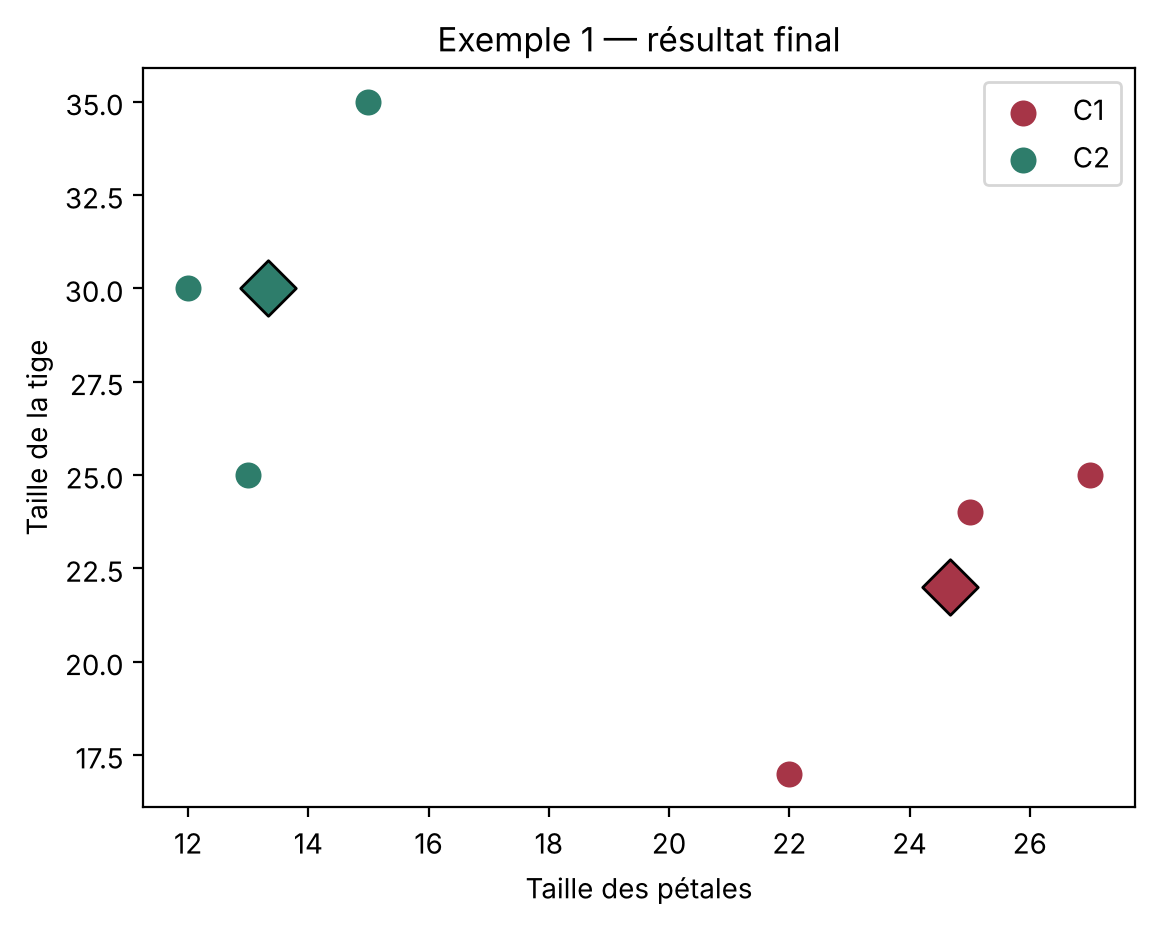

In [10]:
def tracer_clusters(X, etiquettes, centroides, titre, ax=None):
    """Nuage de points coloré par cluster + centroïdes en losange."""
    ax = ax or plt.gca()
    couleurs = ["#A63547", "#2E7D6B", "#E8A33D", "#58595B"]
    for k in range(len(centroides)):
        ax.scatter(*X[etiquettes == k].T, s=70, color=couleurs[k], label=f"C{k+1}")
        ax.scatter(*centroides[k], s=200, marker="D", color=couleurs[k], edgecolor="black")
    ax.set_xlabel("Taille des pétales"); ax.set_ylabel("Taille de la tige")
    ax.set_title(titre); ax.legend()

tracer_clusters(X_fleurs, etiquettes_ex1, centroides_ex1, "Exemple 1 — résultat final")
plt.show()

### 4.4 Vérification avec scikit-learn

*scikit-learn arrive-t-il au même résultat ?*

On impose les **mêmes centroïdes initiaux** (`init=...`) et un seul lancement (`n_init=1`).

In [11]:
modele = KMeans(n_clusters=2, init=init_ex1, n_init=1, random_state=42)
modele.fit(X_fleurs)

print("Centroïdes sklearn :", np.round(modele.cluster_centers_, 2).tolist())
print("Groupes sklearn    :", modele.labels_)
print("Inertie sklearn    :", round(modele.inertia_, 2))   # = W de notre implémentation

Centroïdes sklearn : [[24.67, 22.0], [13.33, 30.0]]
Groupes sklearn    : [0 0 0 1 1 1]
Inertie sklearn    : 105.33


💡 `inertia_` est exactement notre $W$ (somme des **carrés** des distances).

### 4.5 Silhouette à la main pour $O_1$

*La fleur O1 est-elle bien dans son groupe ?*

$O_1$ est dans $C_1 = \{O_1, O_2, O_3\}$ ; le cluster voisin est $C_2$.

In [12]:
d_O1 = np.sqrt(((X_fleurs - X_fleurs[0]) ** 2).sum(axis=1))   # distances de O1 aux 6 points
a = d_O1[[1, 2]].mean()         # moyenne vers O2, O3 (son cluster)
b = d_O1[[3, 4, 5]].mean()      # moyenne vers O4, O5, O6 (cluster voisin)
s = (b - a) / max(a, b)
print(f"a(O1) = {a:.2f}   b(O1) = {b:.2f}   s(O1) = {s:.2f}")

# Vérification avec scikit-learn
print("sklearn :", silhouette_samples(X_fleurs, etiquettes_ex1).round(2))

a(O1) = 8.52   b(O1) = 15.92   s(O1) = 0.46
sklearn : [0.46 0.61 0.64 0.52 0.4  0.65]


## 5. Le piège de l'initialisation : minimum local

*Et si l'on change seulement les centres de départ ?*

**Exemple 2 du cours** : mêmes données, mais centroïdes initiaux $\mu_1 = (30, 13)$ et $\mu_2 = (33, 19)$.

In [13]:
init_ex2 = np.array([[30, 13], [33, 19]])
centroides_ex2, etiquettes_ex2, W_ex2 = kmeans_scratch(X_fleurs, init_ex2)
print("Évolution de W :", np.round(W_ex2, 2).tolist())

--- Itération 1 --- centroïdes : [[30.0, 13.0], [33.0, 19.0]]
    d(., mu1)  d(., mu2) Groupe
O1       8.94      11.18     C1
O2      12.37       8.49     C2
O3      12.08       9.43     C2
O4      26.63      24.08     C2
O5      20.81      20.88     C1
O6      24.76      23.71     C2
Inertie W = 1816.00

--- Itération 2 --- centroïdes : [[17.5, 21.0], [19.75, 28.5]]
    d(., mu1)  d(., mu2) Groupe
O1       6.02      11.72     C1
O2      10.31       8.05     C2
O3       8.08       6.91     C2
O4      14.22       8.05     C2
O5       6.02       7.60     C1
O6      10.55       7.89     C2
Inertie W = 312.25

Convergence atteinte à l'itération 2.
Évolution de W : [1816.0, 312.25]


L'algorithme converge… mais vers $W = 312.25$, presque **3 fois plus** que l'exemple 1. Comparons les deux partitions :

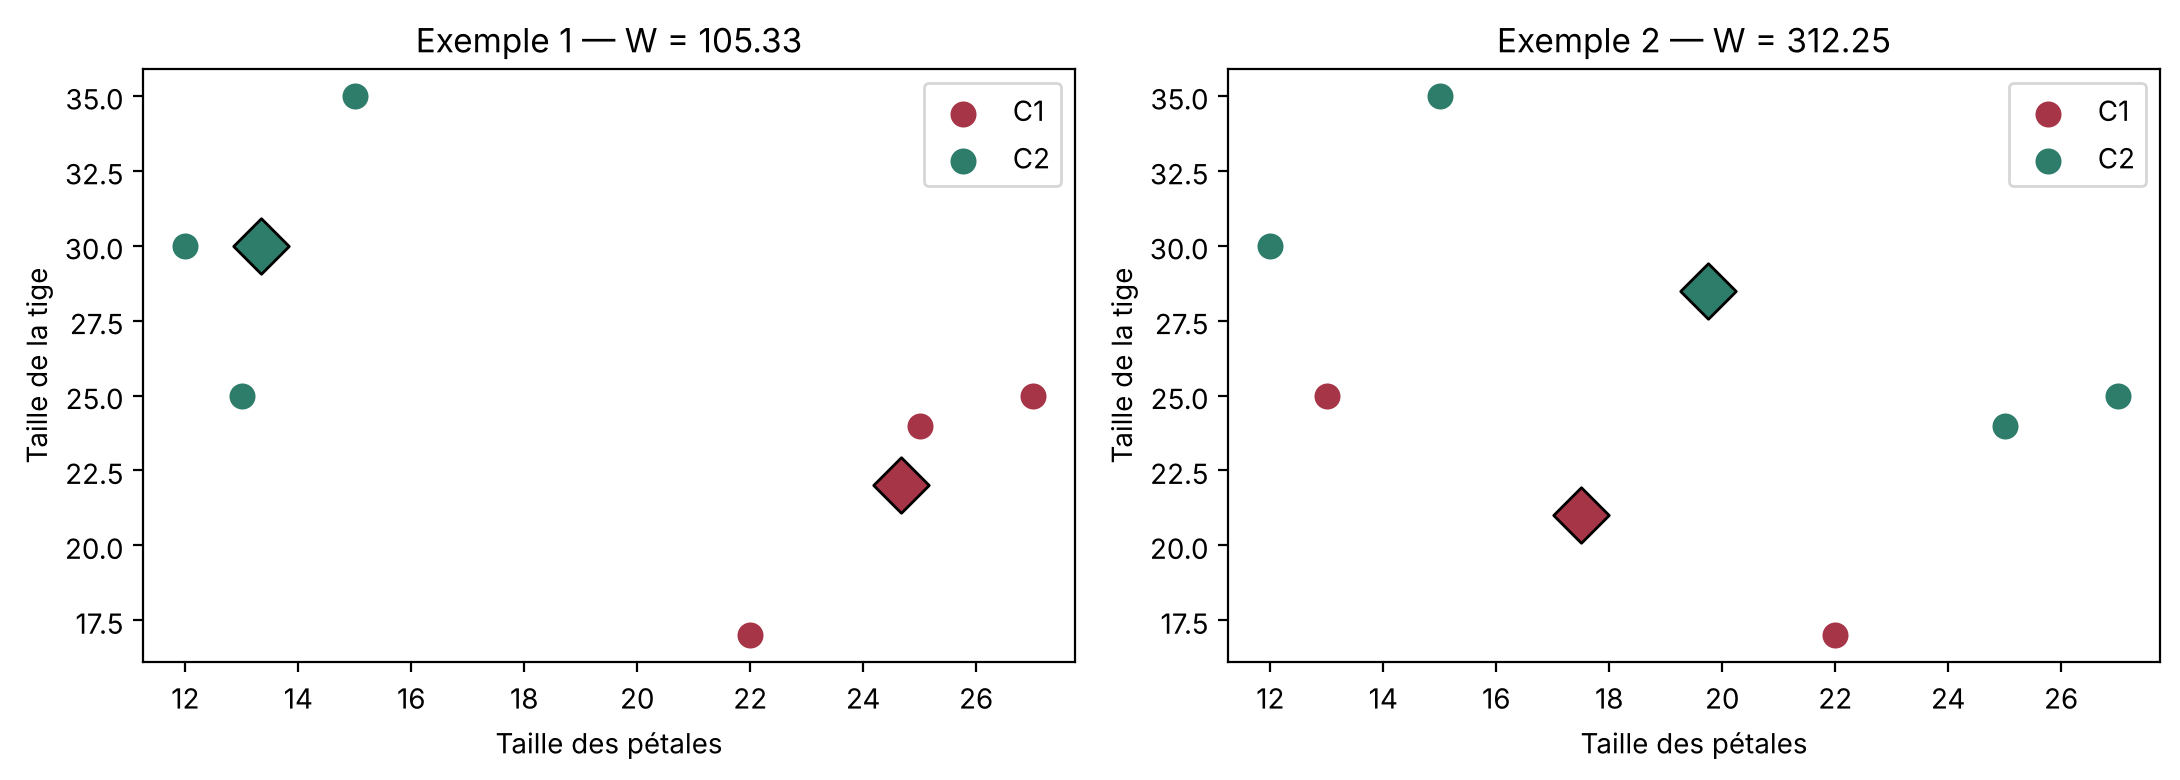

Silhouette exemple 1 : 0.55
Silhouette exemple 2 : 0.00


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
tracer_clusters(X_fleurs, etiquettes_ex1, centroides_ex1, f"Exemple 1 — W = {W_ex1[-1]:.2f}", axes[0])
tracer_clusters(X_fleurs, etiquettes_ex2, centroides_ex2, f"Exemple 2 — W = {W_ex2[-1]:.2f}", axes[1])
plt.tight_layout(); plt.show()

print(f"Silhouette exemple 1 : {silhouette_score(X_fleurs, etiquettes_ex1):.2f}")
print(f"Silhouette exemple 2 : {silhouette_score(X_fleurs, etiquettes_ex2):.2f}")

**Solution** : lancer K-means plusieurs fois (`n_init`) avec l'initialisation **K-means++** (option par défaut de scikit-learn), puis garder le meilleur $W$.

In [15]:
# 10 lancements avec K-means++ : on garde automatiquement le meilleur W
modele = KMeans(n_clusters=2, init="k-means++", n_init=10, random_state=42)
modele.fit(X_fleurs)
print("Meilleure inertie trouvée :", round(modele.inertia_, 2))   # 105.33 : le minimum global

Meilleure inertie trouvée : 105.33


## 6. Cas pratique : la base Iris

*Passons à 150 fleurs : K-means retrouvera-t-il les trois espèces sans les connaître ?*

150 fleurs d'iris décrites par 4 mesures (en cm). Les vraies espèces existent, mais **on ne les donne pas** à K-means : on les utilisera seulement à la fin pour évaluer le résultat.

In [16]:
iris = load_iris()
X_iris = iris.data                 # 150 x 4 : longueur/largeur des sépales et des pétales
y_iris = iris.target               # vraies espèces (0, 1, 2), non utilisées pour l'apprentissage

df_iris = pd.DataFrame(X_iris, columns=iris.feature_names)
df_iris.describe().round(2)

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.00,150.00,150.00,150.00
mean,5.84,3.06,3.76,1.20
std,0.83,0.44,1.77,0.76
min,4.30,2.00,1.00,0.10
25%,5.10,2.80,1.60,0.30
50%,5.80,3.00,4.35,1.30
75%,6.40,3.30,5.10,1.80
max,7.90,4.40,6.90,2.50


### 6.1 Choisir $K$ : la méthode du coude

*Combien de groupes faut-il chercher ?*

On lance K-means pour $K = 1, \dots, 8$ et on trace l'inertie $W$.

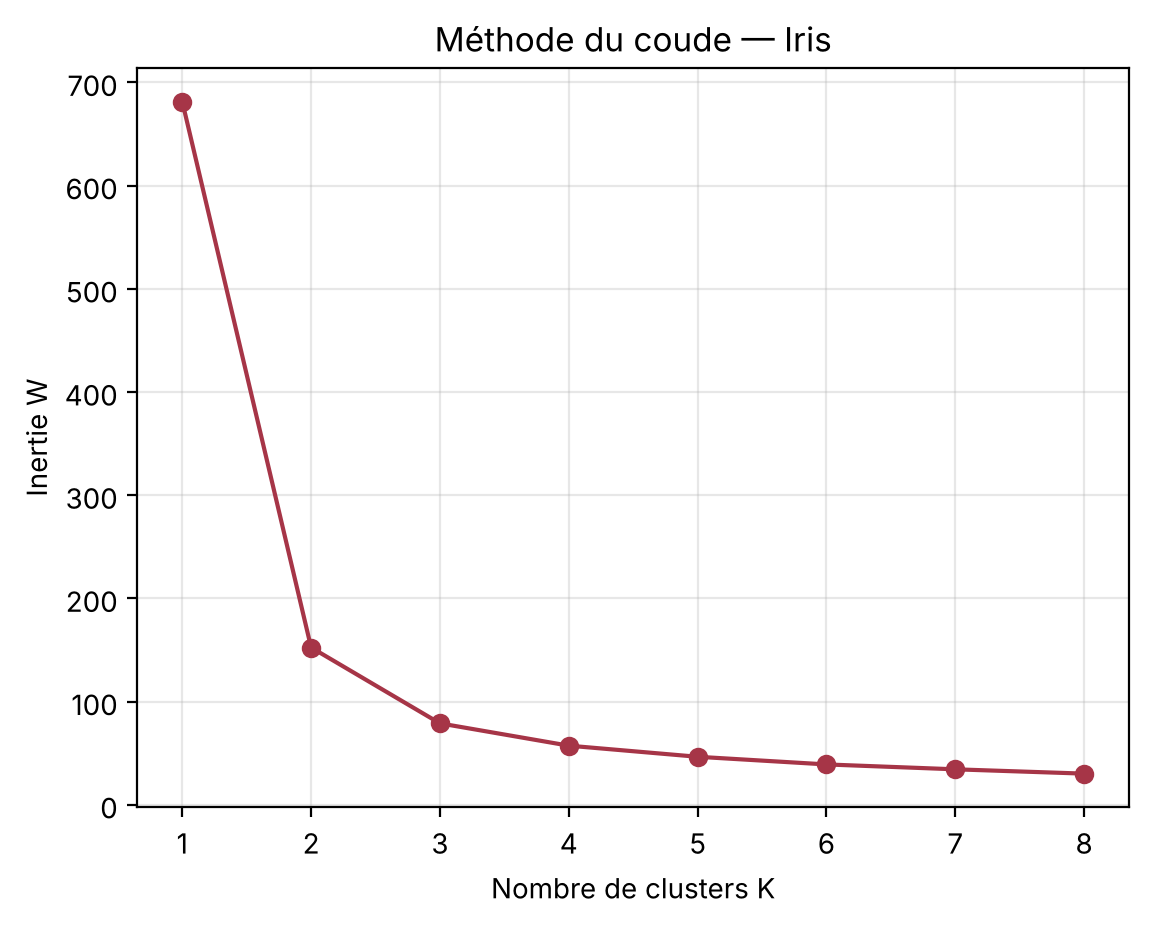

In [17]:
valeurs_K = range(1, 9)
inerties = []
for K in valeurs_K:
    km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_iris)
    inerties.append(km.inertia_)          # W pour ce K

plt.plot(valeurs_K, inerties, "o-", color="#A63547")
plt.xlabel("Nombre de clusters K"); plt.ylabel("Inertie W")
plt.title("Méthode du coude — Iris"); plt.grid(alpha=0.3)
plt.show()

La courbe « casse » nettement à $K = 3$ : c'est le **coude**.

### 6.2 Choisir $K$ : le score de silhouette

*La silhouette est-elle d'accord avec le coude ?*

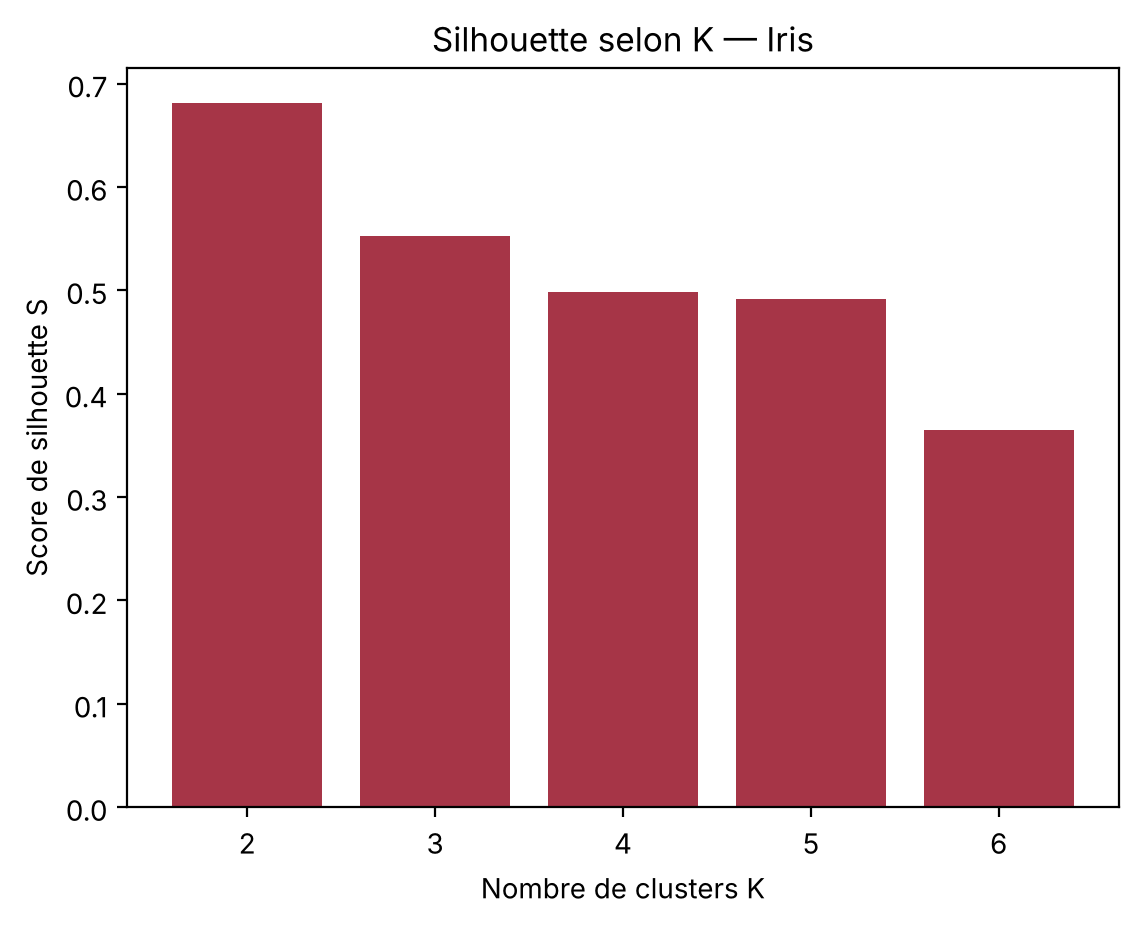

{2: 0.681, 3: 0.553, 4: 0.498, 5: 0.491, 6: 0.365}


In [18]:
valeurs_K = range(2, 7)                   # la silhouette n'existe pas pour K = 1
scores = []
for K in valeurs_K:
    km = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_iris)
    scores.append(silhouette_score(X_iris, km.labels_))

plt.bar(valeurs_K, scores, color="#A63547")
plt.xlabel("Nombre de clusters K"); plt.ylabel("Score de silhouette S")
plt.title("Silhouette selon K — Iris")
plt.show()
print({K: round(float(sc), 3) for K, sc in zip(valeurs_K, scores)})

⚠️ La silhouette préfère $K = 2$, le coude $K = 3$. Les deux espèces *versicolor* et *virginica* se chevauchent : les critères ne sont pas toujours d'accord, il faut aussi la connaissance du domaine. Ici, on sait qu'il y a 3 espèces : on garde $K = 3$.

### 6.3 Modèle final avec $K = 3$

*On retient trois groupes : regardons ce qu'ils contiennent.*

In [19]:
km3 = KMeans(n_clusters=3, n_init=10, random_state=42)
etiquettes_iris = km3.fit_predict(X_iris)       # apprentissage + affectation

print("Inertie W :", round(km3.inertia_, 2))
print("Taille des clusters :", np.bincount(etiquettes_iris))

Inertie W : 78.85
Taille des clusters : [62 50 38]


Visualisation sur les deux variables les plus informatives (longueur et largeur des pétales) :

*Remarque : les numéros (donc les couleurs) des clusters sont arbitraires ; seuls les regroupements comptent.*

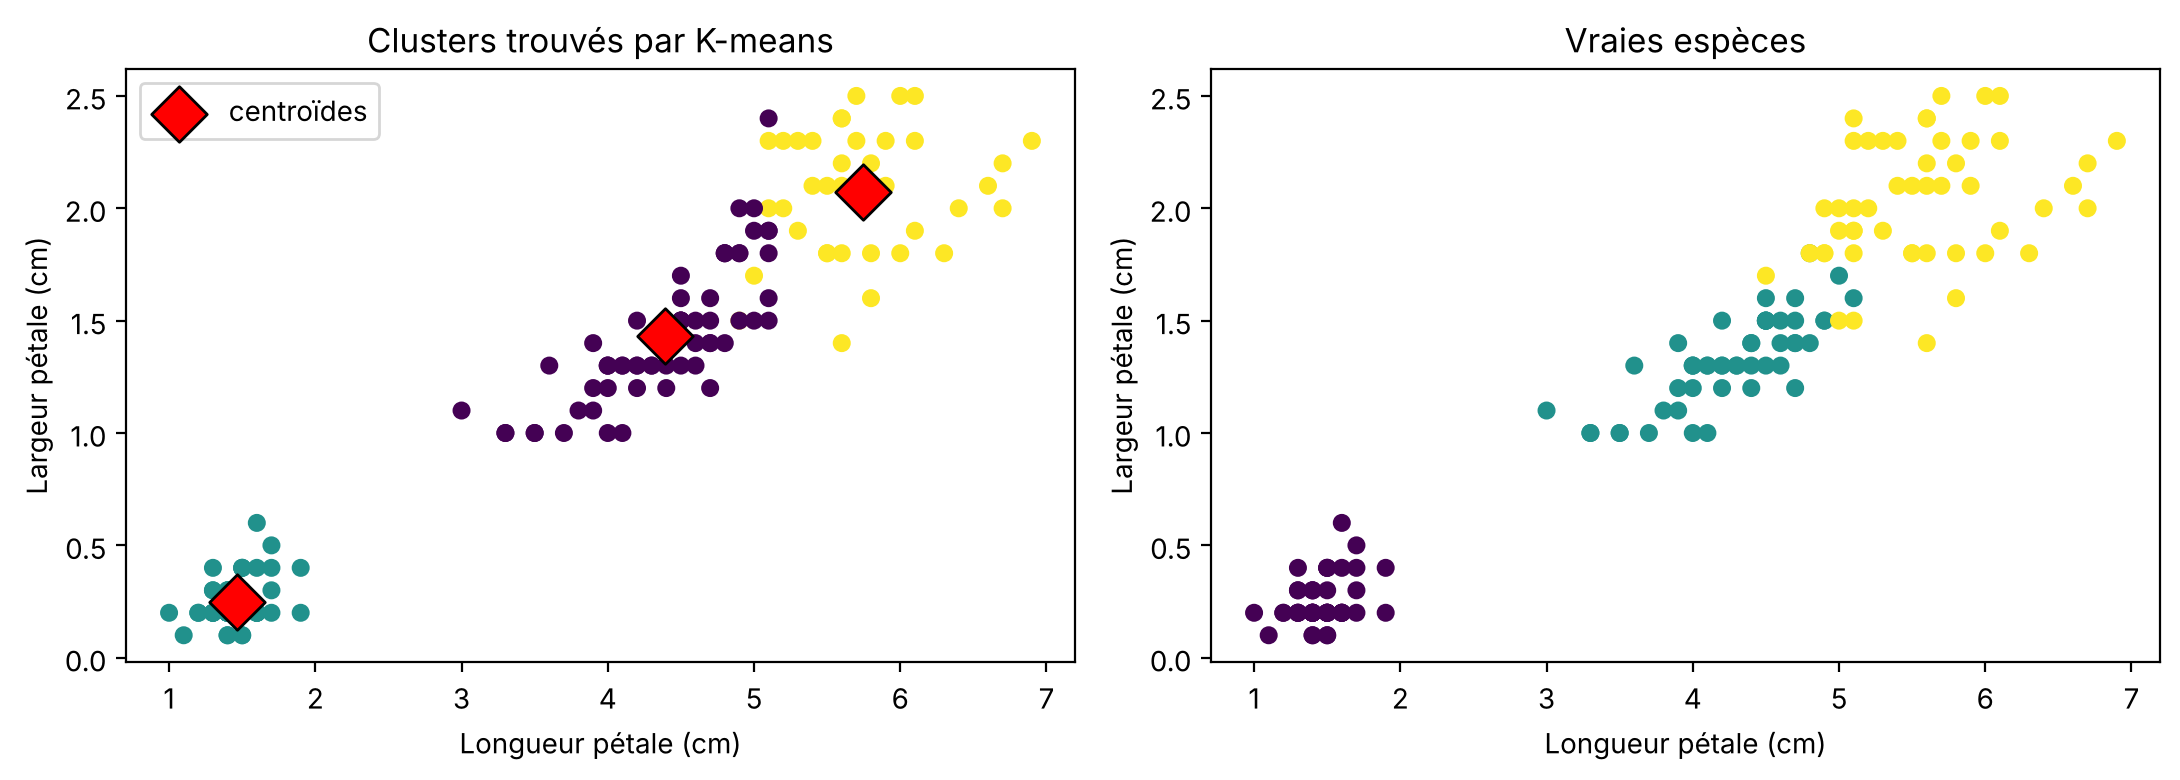

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(X_iris[:, 2], X_iris[:, 3], c=etiquettes_iris, cmap="viridis", s=30)
axes[0].scatter(km3.cluster_centers_[:, 2], km3.cluster_centers_[:, 3],
                marker="D", s=200, c="red", edgecolor="black", label="centroïdes")
axes[0].set_title("Clusters trouvés par K-means"); axes[0].legend()
axes[1].scatter(X_iris[:, 2], X_iris[:, 3], c=y_iris, cmap="viridis", s=30)
axes[1].set_title("Vraies espèces")
for ax in axes:
    ax.set_xlabel("Longueur pétale (cm)"); ax.set_ylabel("Largeur pétale (cm)")
plt.tight_layout(); plt.show()

### 6.4 Évaluation

*Ici, exceptionnellement, on connaît les vraies espèces : comparons.*

En apprentissage non supervisé, on n'a normalement pas les vraies classes. Ici on les a : on peut donc comparer.

- **Tableau croisé** clusters × espèces ;
- **Indice de Rand ajusté (ARI)** : 1 = partition identique aux espèces, 0 = hasard. Il ne dépend pas des numéros donnés aux clusters.

In [21]:
tableau = pd.crosstab(etiquettes_iris, iris.target_names[y_iris],
                      rownames=["Cluster"], colnames=["Espèce"])
print(tableau, "\n")
print("ARI        :", round(adjusted_rand_score(y_iris, etiquettes_iris), 3))
print("Silhouette :", round(silhouette_score(X_iris, etiquettes_iris), 3))

Espèce   setosa  versicolor  virginica
Cluster                               
0             0          48         14
1            50           0          0
2             0           2         36 

ARI        : 0.73
Silhouette : 0.553


*Setosa* est parfaitement isolée ; quelques *versicolor* et *virginica* sont mélangées, ce qui confirme leur chevauchement.

## 7. Influence des hyperparamètres : `init` et `n_init`

*Le hasard de l'initialisation pèse-t-il beaucoup ?*

Avec une initialisation **aléatoire** et **un seul lancement**, le résultat dépend du hasard. On répète 10 fois avec des graines différentes :

In [22]:
resultats = []
for graine in range(10):
    km = KMeans(n_clusters=3, init="random", n_init=1, random_state=graine).fit(X_iris)
    resultats.append(round(km.inertia_, 2))
print("Inertie (init aléatoire, 1 lancement) :", resultats)

km_best = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=42).fit(X_iris)
print("K-means++ avec n_init=10              :", round(km_best.inertia_, 2))

Inertie (init aléatoire, 1 lancement) : [78.85, 78.86, 78.86, 78.85, 78.86, 142.75, 78.86, 78.86, 78.85, 78.86]
K-means++ avec n_init=10              : 78.85


Certains lancements restent bloqués dans un minimum local (inertie plus grande). Avec `k-means++` et `n_init=10`, on obtient la meilleure valeur de façon fiable.

## 8. Exercices

*À vous de jouer ! Les exercices sont classés du plus simple au plus exigeant. Essayez de les faire sans regarder les solutions.*

### Exercice 1 (facile) — K = 3 sur les 6 fleurs

Appliquez `kmeans_scratch` aux 6 fleurs avec $K = 3$ et les centroïdes initiaux $(22, 17)$, $(27, 25)$ et $(15, 35)$.
1. Combien d'itérations faut-il ?
2. Quelle est l'inertie finale ? Est-elle plus petite qu'avec $K = 2$ ? Pourquoi est-ce toujours le cas ?

In [23]:
# À compléter
init_k3 = ...

### Exercice 2 (moyen) — L'effet de la standardisation

K-means utilise des distances : une variable avec de grandes valeurs domine les autres.
1. Standardisez `X_iris` avec `StandardScaler`.
2. Relancez la méthode du coude et la silhouette sur les données standardisées.
3. Comparez l'ARI obtenu avec $K = 3$ sur les données brutes et standardisées.

In [24]:
# À compléter
scaler = StandardScaler()
X_iris_std = ...

### Exercice 3 (défi) — Implémenter l'initialisation K-means++

Écrivez une fonction `init_kmeans_pp(X, K, graine)` qui :
1. choisit le premier centroïde au hasard parmi les points ;
2. calcule, pour chaque point, $D(x)$ = distance au centroïde déjà choisi le plus proche ;
3. tire le centroïde suivant avec une probabilité proportionnelle à $D(x)^2$ ;
4. répète jusqu'à avoir $K$ centroïdes.

Utilisez-la avec `kmeans_scratch` sur les 6 fleurs : retrouvez-vous $W = 105.33$ ?

In [25]:
# À compléter
def init_kmeans_pp(X, K, graine=42):
    rng = np.random.default_rng(graine)
    ...

## 9. Solutions

*Comparez vos réponses avec les propositions ci-dessous ; il existe souvent plusieurs façons correctes de faire.*

<details>
<summary><b>Solution de l'exercice 1</b> (cliquer pour afficher)</summary>

```python
init_k3 = np.array([[22, 17], [27, 25], [15, 35]])
centroides_k3, etiquettes_k3, W_k3 = kmeans_scratch(X_fleurs, init_k3)
print("Inertie finale :", round(W_k3[-1], 2))
```

L'inertie est plus petite qu'avec $K = 2$ : plus il y a de centroïdes, plus chaque point est proche du sien. $W$ diminue toujours quand $K$ augmente (et vaut 0 si $K = n$). C'est pour cela qu'on cherche un **coude** et non le minimum de $W$.
</details>

<details>
<summary><b>Solution de l'exercice 2</b> (cliquer pour afficher)</summary>

```python
scaler = StandardScaler()
X_iris_std = scaler.fit_transform(X_iris)          # moyenne 0, écart-type 1

for nom, donnees in [("brutes", X_iris), ("standardisées", X_iris_std)]:
    km = KMeans(n_clusters=3, n_init=10, random_state=42).fit(donnees)
    print(nom, "-> ARI =", round(adjusted_rand_score(y_iris, km.labels_), 3),
          "| silhouette =", round(silhouette_score(donnees, km.labels_), 3))
```

Sur Iris, les 4 variables sont déjà en cm et d'échelles proches : la standardisation change peu le résultat (elle peut même le dégrader un peu, car elle donne autant de poids aux sépales, moins discriminants, qu'aux pétales). Sur des variables d'unités différentes (âge en années, revenu en dirhams…), elle est indispensable.
</details>

<details>
<summary><b>Solution de l'exercice 3</b> (cliquer pour afficher)</summary>

```python
def init_kmeans_pp(X, K, graine=42):
    rng = np.random.default_rng(graine)
    centroides = [X[rng.integers(len(X))]]                 # 1er centre au hasard
    while len(centroides) < K:
        D = calculer_distances(X, np.array(centroides)).min(axis=1)  # distance au plus proche
        probas = D ** 2 / np.sum(D ** 2)                   # proba proportionnelle à D(x)^2
        centroides.append(X[rng.choice(len(X), p=probas)])
    return np.array(centroides)

init_pp = init_kmeans_pp(X_fleurs, 2)
print("Centroïdes initiaux K-means++ :", init_pp.tolist())
kmeans_scratch(X_fleurs, init_pp, afficher=False)[2]   # historique de W
```

Les centres initiaux sont éloignés l'un de l'autre, ce qui évite en général le minimum local de l'exemple 2.
</details>

## 10. Conclusion — ce qu'il faut retenir

*Avant de passer à la suite, prenons une minute pour résumer l'essentiel.*

- K-means alterne deux étapes : **affecter** chaque point au centroïde le plus proche, puis **recalculer** les centroïdes.
- Il minimise l'inertie $W$ (`inertia_` dans scikit-learn) et converge toujours, mais parfois vers un **minimum local**.
- On se protège avec **K-means++** et plusieurs lancements (`n_init`).
- $K$ se choisit en croisant la **méthode du coude**, le **score de silhouette** et la connaissance du domaine.
- Les données doivent être **quantitatives**, et souvent **standardisées**.

➡️ Prochain cours : le clustering hiérarchique ascendant (CAH), sur les mêmes 6 fleurs.